# Notebook 12 — Publication-Quality Research Visualization

## WR-MovementIQ

**Beyond the 40-Yard Dash: Linking NFL Combine Receiver Movement Mechanics to Regular-Season Performance Using Player Tracking Data**

### Purpose

This notebook converts independently audited research results into publication-quality figures.

It does not:
- Retrain models
- Tune hyperparameters
- Change player eligibility
- Modify predictions
- Recalculate the primary research models

### Research outputs

1. Nested-CV speed performance
2. Nested-CV performance across all outcomes
3. P95 speed receiver-level uncertainty
4. Peak speed receiver-level uncertainty
5. Mean speed LOCO performance
6. P95 speed LOCO performance
7. Peak speed LOCO performance
8. Predictor association heatmap
9. Tracking-feature ablation
10. Eligibility sample-size sensitivity
11. Model stability
12. Coefficient stability

Every figure is exported in PNG and PDF formats.

**Research principle:** Visualizations must preserve uncertainty, sample limitations and the distinction between association and prediction.


In [1]:

# ============================================================
# 1. ENVIRONMENT AND ROOT DETECTION
# ============================================================

from pathlib import Path
import json
import hashlib
import platform
import sys
import struct
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CURRENT_DIR = Path.cwd().resolve()

candidates = [
    CURRENT_DIR,
    CURRENT_DIR.parent,
]

ROOT = next(
    (
        candidate
        for candidate in candidates
        if (
            candidate
            / "reports"
            / "final_results_synthesis"
            / "tables"
            / "main_nested_cv_performance.csv"
        ).is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Cannot locate WR-MovementIQ project root. "
        f"Current directory: {CURRENT_DIR}"
    )

print("Project root:", ROOT)

SOURCE_DIR = ROOT / "reports" / "final_results_synthesis" / "tables"

OUT = ROOT / "reports" / "publication_visualizations"
PNG_DIR = OUT / "png"
PDF_DIR = OUT / "pdf"
TABLE_DIR = OUT / "tables"

for folder in [OUT, PNG_DIR, PDF_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.titlesize": 14,
})

print("Output directory:", OUT)
print("Python:", sys.version)
print("Platform:", platform.platform())


Project root: D:\PROJECTS\WR-MovementIQ
Output directory: D:\PROJECTS\WR-MovementIQ\reports\publication_visualizations
Python: 3.10.0 (tags/v3.10.0:b494f59, Oct  4 2021, 19:00:18) [MSC v.1929 64 bit (AMD64)]
Platform: Windows-10-10.0.22621-SP0


## 1. Load and validate source data

The source tables are the verified outputs from Notebook 11.


In [2]:

# ============================================================
# 2. LOAD SOURCE TABLES
# ============================================================

SOURCE_FILES = {
    "nested": "main_nested_cv_performance.csv",
    "loco": "loco_performance.csv",
    "decisions": "primary_speed_outcome_decisions.csv",
    "bootstrap": "receiver_level_bootstrap_summary.csv",
    "ablation": "speed_feature_ablation.csv",
    "stability": "sensitivity_fold_stability.csv",
    "eligibility": "eligibility_threshold_comparison.csv",
    "associations": "univariate_spearman_associations.csv",
    "coefficients": "coefficient_stability_summary.csv",
}

DATA = {}
SOURCE_AUDIT = []

for key, filename in SOURCE_FILES.items():

    path = SOURCE_DIR / filename

    if not path.is_file():
        raise FileNotFoundError(
            f"Missing source table: {path}"
        )

    df = pd.read_csv(path)

    DATA[key] = df

    SOURCE_AUDIT.append({
        "source": filename,
        "rows": len(df),
        "columns": len(df.columns),
        "sha256": hashlib.sha256(
            path.read_bytes()
        ).hexdigest(),
    })

nested = DATA["nested"]
loco = DATA["loco"]
decisions = DATA["decisions"]
bootstrap = DATA["bootstrap"]
ablation = DATA["ablation"]
stability = DATA["stability"]
eligibility = DATA["eligibility"]
associations = DATA["associations"]
coefficients = DATA["coefficients"]

EXPECTED_ROWS = {
    "nested": 24,
    "loco": 72,
    "decisions": 6,
    "bootstrap": 18,
    "ablation": 15,
    "stability": 54,
    "eligibility": 300,
    "associations": 54,
    "coefficients": 108,
}

for key, expected in EXPECTED_ROWS.items():
    actual = len(DATA[key])

    if actual != expected:
        raise ValueError(
            f"{key}: expected {expected} rows, found {actual}"
        )

print("All nine source tables loaded.")
print("Source row-count checks passed.")

source_audit = pd.DataFrame(SOURCE_AUDIT)

source_audit.to_csv(
    TABLE_DIR / "source_inventory.csv",
    index=False,
)

display(source_audit)


All nine source tables loaded.
Source row-count checks passed.


,source,rows,columns,sha256
0,main_nested_cv_performance.csv,24,7,bd46802adcb771b2d10f571f1683d8b99323e7b2608b0b...
1,loco_performance.csv,72,8,a96e34f69f76edf231590180877c39450816fb58d6aad9...
2,primary_speed_outcome_decisions.csv,6,19,51de377b36b4eaa249e25c1d32627b338a09cecd852448...
3,receiver_level_bootstrap_summary.csv,18,8,c7468e914df9d8b38ef7168bfdbe78d9875e5e5a815a80...
4,speed_feature_ablation.csv,15,8,9b380b286e6bc21e1129c6b143a97d2f769c253a21f7c2...
5,sensitivity_fold_stability.csv,54,8,bc7622a8437d1ee0b680544c034349b5f2c88bfcde8e25...
6,eligibility_threshold_comparison.csv,300,12,2f18c185ed364866b9c50b173ce907af4f87b4438fc7c7...
7,univariate_spearman_associations.csv,54,5,b09d03c8b6c9abee7ace0056b4d83984b2b172aa4eaea2...
8,coefficient_stability_summary.csv,108,12,f06c4126c0238b20a97b39034e251714001c9c4a876cc0...


## 2. Figure export utility

All figures are saved in both high-resolution PNG and vector PDF formats.


In [3]:

# ============================================================
# 3. FIGURE EXPORT UTILITY
# ============================================================

FIGURE_RECORDS = []

def export_figure(fig, figure_id, title, caption):

    png_path = PNG_DIR / f"{figure_id}.png"
    pdf_path = PDF_DIR / f"{figure_id}.pdf"

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white",
    )

    FIGURE_RECORDS.append({
        "figure_id": figure_id,
        "title": title,
        "caption": caption,
        "png_path": str(png_path.relative_to(ROOT)),
        "pdf_path": str(pdf_path.relative_to(ROOT)),
        "png_bytes": png_path.stat().st_size,
        "pdf_bytes": pdf_path.stat().st_size,
        "png_sha256": hashlib.sha256(
            png_path.read_bytes()
        ).hexdigest(),
        "pdf_sha256": hashlib.sha256(
            pdf_path.read_bytes()
        ).hexdigest(),
    })

    plt.show()
    plt.close(fig)

    print("Exported:", figure_id)


MODEL_ORDER = [
    "BASELINE",
    "TRADITIONAL",
    "TRACKING",
    "COMBINED",
]

SPEED_OUTCOMES = [
    "game_mean_speed_raw_median",
    "game_p95_speed_raw_median",
    "game_peak_speed_raw_median",
]

OUTCOME_LABELS = {
    "game_mean_speed_raw_median": "Mean game speed",
    "game_p95_speed_raw_median": "95th-percentile game speed",
    "game_peak_speed_raw_median": "Peak game speed",
    "game_mean_acceleration_raw_median": "Mean game acceleration",
    "game_peak_acceleration_raw_median": "Peak game acceleration",
    "game_path_efficiency_median": "Game path efficiency",
}

def outcome_label(value):
    return OUTCOME_LABELS.get(
        value,
        str(value).replace("_", " ").title(),
    )

def save_bar_figure(
    df,
    category_col,
    value_col,
    title,
    ylabel,
    figure_id,
    caption,
    order=None,
    rotation=15,
):
    plot_df = df.copy()

    plot_df[value_col] = pd.to_numeric(
        plot_df[value_col],
        errors="coerce",
    )

    if order is not None:
        plot_df[category_col] = pd.Categorical(
            plot_df[category_col],
            categories=order,
            ordered=True,
        )
        plot_df = plot_df.sort_values(category_col)

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.bar(
        plot_df[category_col].astype(str),
        plot_df[value_col],
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=rotation)
    ax.grid(axis="y", alpha=0.25)

    export_figure(
        fig,
        figure_id,
        title,
        caption,
    )


## 3. Main nested-CV model performance

Figures 1–3 compare predictive MAE for the three primary speed outcomes.


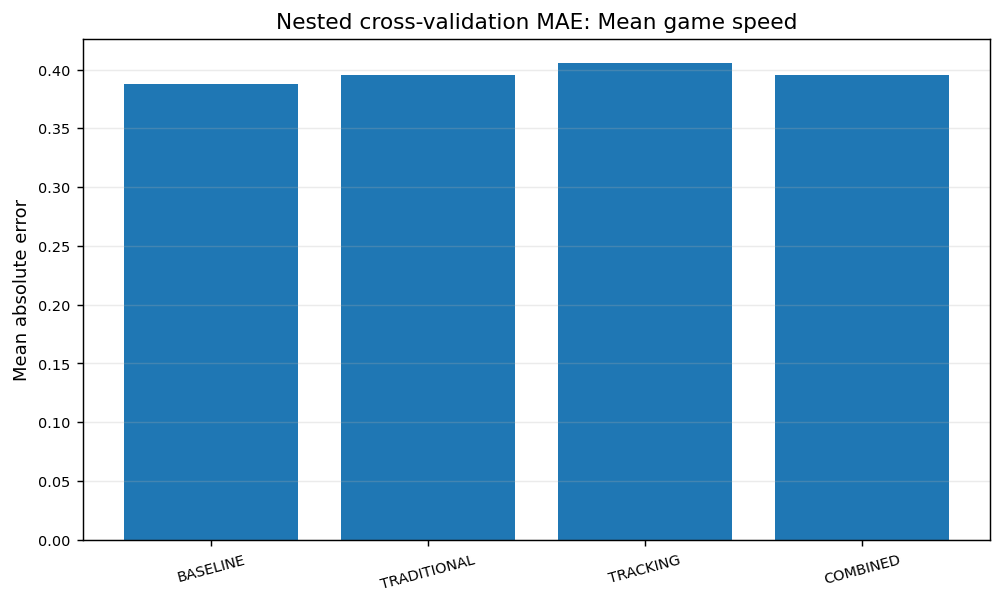

Exported: figure_01_nested_game_mean_speed_raw_median


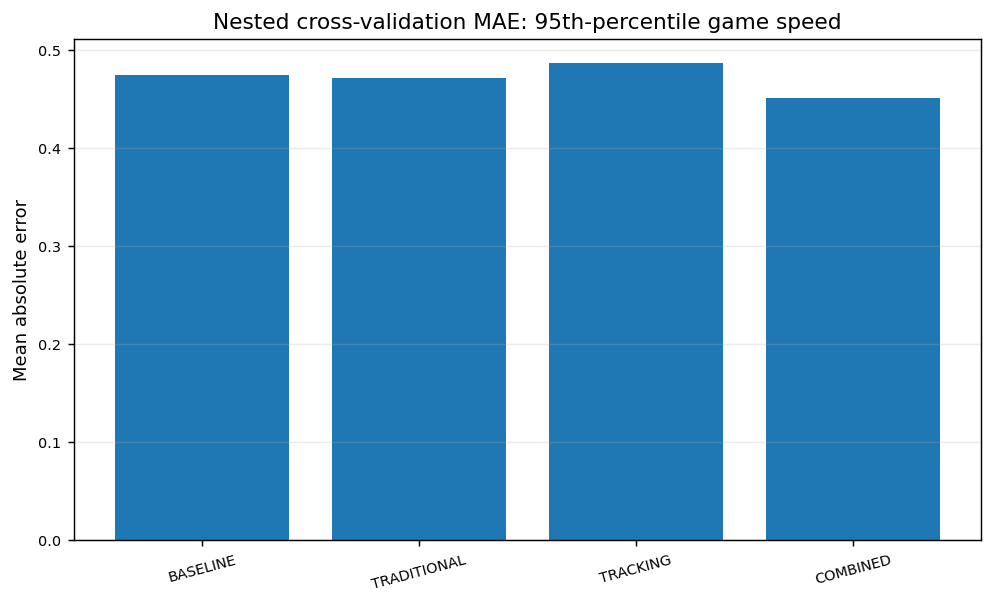

Exported: figure_02_nested_game_p95_speed_raw_median


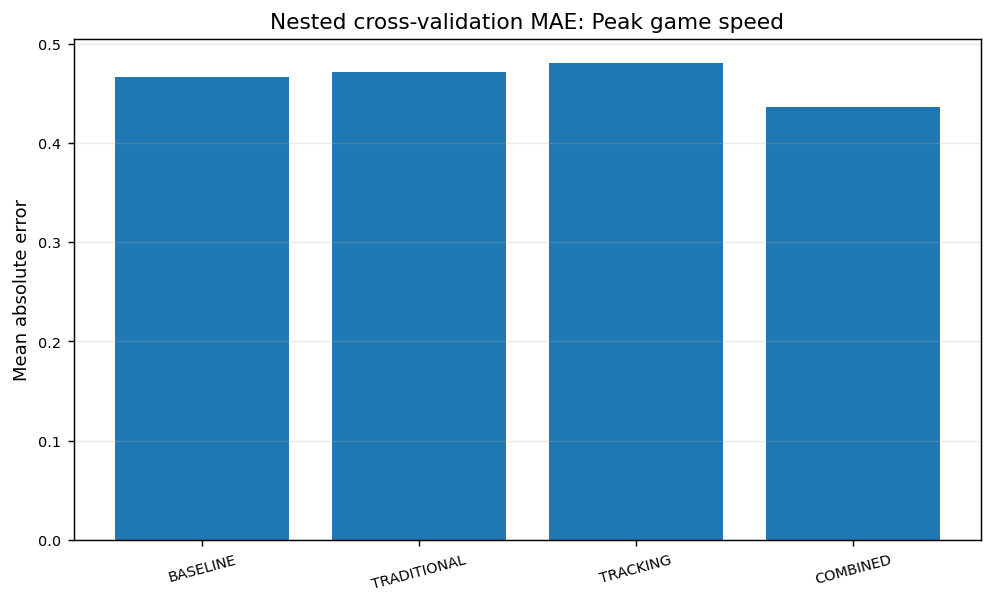

Exported: figure_03_nested_game_peak_speed_raw_median


In [4]:

# ============================================================
# FIGURES 1–3: NESTED CV SPEED PERFORMANCE
# ============================================================

for outcome in SPEED_OUTCOMES:

    subset = nested[
        nested["outcome"] == outcome
    ].copy()

    save_bar_figure(
        subset,
        "model",
        "mae",
        f"Nested cross-validation MAE: {outcome_label(outcome)}",
        "Mean absolute error",
        f"figure_{len(FIGURE_RECORDS)+1:02d}_nested_{outcome}",
        (
            "Out-of-fold mean absolute error for the baseline, "
            "traditional Combine, tracking-derived and combined "
            "Ridge models. Evaluation uses 93 player-seasons "
            "from 54 receivers."
        ),
        order=MODEL_ORDER,
    )


## 4. Overall nested-CV performance across six outcomes

Figure 4 provides a model-by-outcome MAE comparison. The outcome scales differ, so this is a descriptive comparison rather than a common-scale aggregate score.


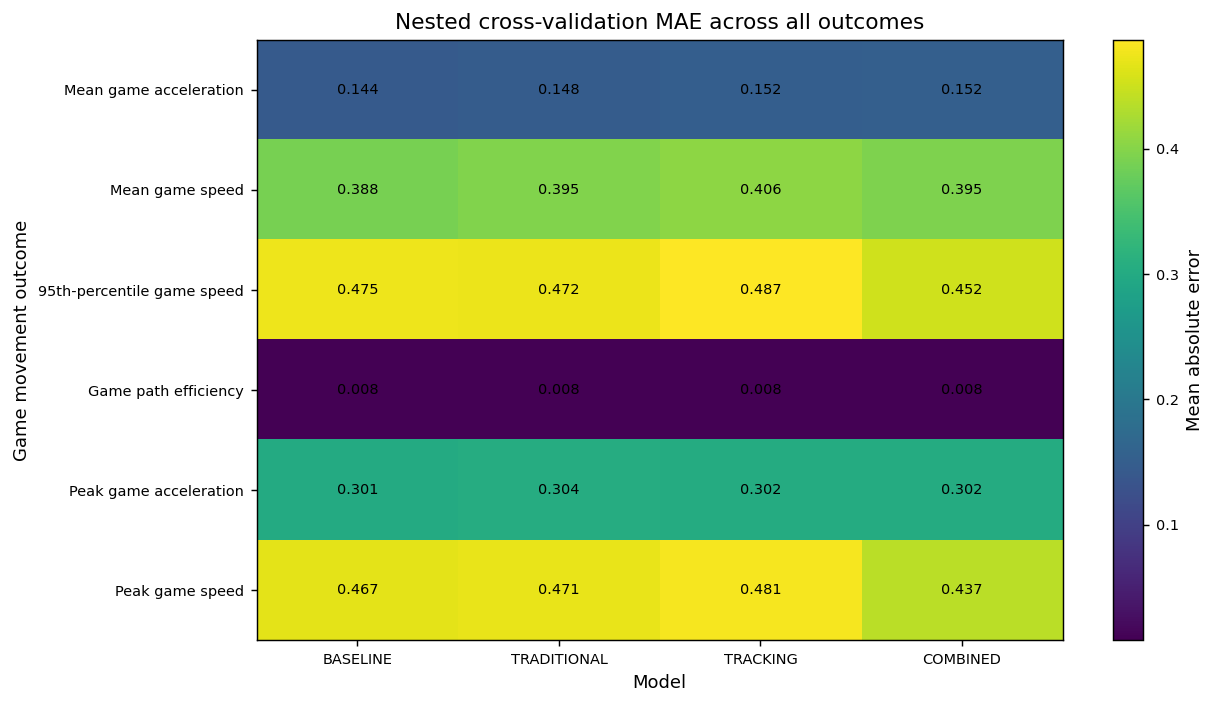

Exported: figure_04_all_outcome_mae_heatmap


In [5]:

# ============================================================
# FIGURE 4: ALL-OUTCOME PERFORMANCE HEATMAP
# ============================================================

heat = nested.pivot(
    index="outcome",
    columns="model",
    values="mae",
)

heat = heat.reindex(columns=MODEL_ORDER)

fig, ax = plt.subplots(figsize=(10, 6))

im = ax.imshow(
    heat.to_numpy(dtype=float),
    aspect="auto",
)

ax.set_xticks(np.arange(len(heat.columns)))
ax.set_xticklabels(heat.columns)

ax.set_yticks(np.arange(len(heat.index)))
ax.set_yticklabels([
    outcome_label(x) for x in heat.index
])

for i in range(len(heat.index)):
    for j in range(len(heat.columns)):
        value = heat.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=8,
        )

ax.set_title("Nested cross-validation MAE across all outcomes")
ax.set_xlabel("Model")
ax.set_ylabel("Game movement outcome")

fig.colorbar(
    im,
    ax=ax,
    label="Mean absolute error",
)

export_figure(
    fig,
    "figure_04_all_outcome_mae_heatmap",
    "Nested cross-validation MAE across all outcomes",
    (
        "Heatmap of out-of-fold MAE for six game movement "
        "outcomes and four model specifications. Outcomes "
        "have different measurement scales and should not "
        "be compared as though they shared a common unit."
    ),
)


## 5. Receiver-level bootstrap uncertainty

Figures 5 and 6 show the primary P95 and peak speed comparisons.

Negative MAE differences favour the evaluated model. Confidence intervals crossing zero indicate uncertainty about incremental improvement.


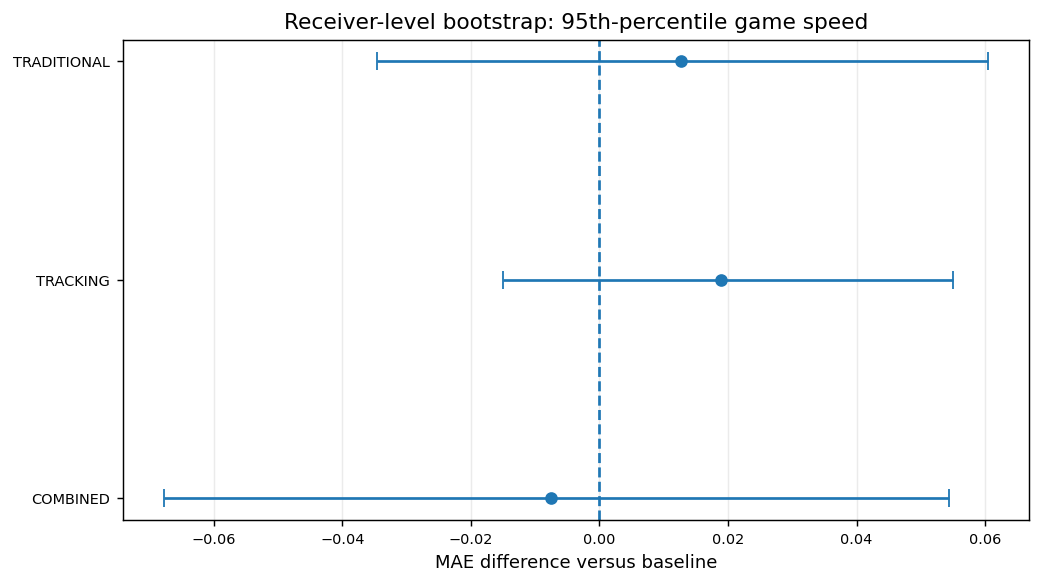

Exported: figure_05_bootstrap_game_p95_speed_raw_median


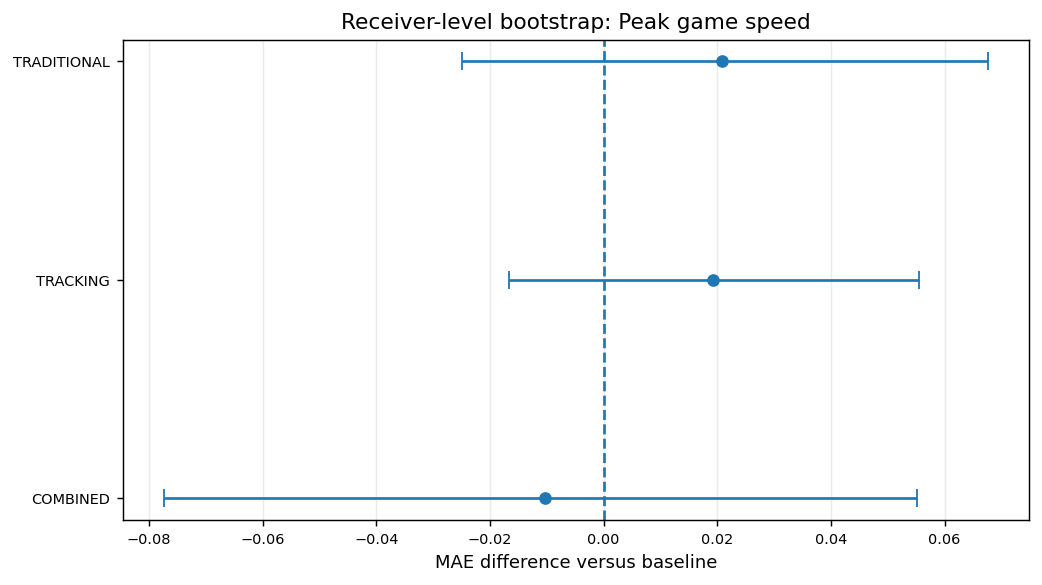

Exported: figure_06_bootstrap_game_peak_speed_raw_median


In [6]:

# ============================================================
# FIGURES 5–6: BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

for outcome in SPEED_OUTCOMES[1:]:

    subset = decisions[
        decisions["outcome"] == outcome
    ].copy()

    subset = subset.sort_values("model")

    x = pd.to_numeric(
        subset["point_estimate"]
    ).to_numpy(dtype=float)

    lower = (
        x - pd.to_numeric(
            subset["ci_2_5"]
        ).to_numpy(dtype=float)
    )

    upper = (
        pd.to_numeric(
            subset["ci_97_5"]
        ).to_numpy(dtype=float) - x
    )

    y = np.arange(len(subset))

    fig, ax = plt.subplots(figsize=(9, 4.8))

    ax.errorbar(
        x,
        y,
        xerr=[lower, upper],
        fmt="o",
        capsize=5,
    )

    ax.axvline(
        0,
        linestyle="--",
    )

    ax.set_yticks(y)
    ax.set_yticklabels(subset["model"])

    ax.set_xlabel(
        "MAE difference versus baseline"
    )

    ax.set_title(
        f"Receiver-level bootstrap: {outcome_label(outcome)}"
    )

    ax.grid(axis="x", alpha=0.25)

    export_figure(
        fig,
        f"figure_{len(FIGURE_RECORDS)+1:02d}_bootstrap_{outcome}",
        f"Receiver-level bootstrap: {outcome_label(outcome)}",
        (
            "Receiver-level bootstrap comparison of MAE "
            "differences versus baseline, using 5,000 "
            "replicates and fold-stratified resampling. "
            "Negative differences favour the evaluated model. "
            "Intervals crossing zero do not establish "
            "a reliable improvement."
        ),
    )


## 6. Leave-one-draft-cohort-out performance

Figures 7–9 display cohort-held-out MAE for the three primary speed outcomes.


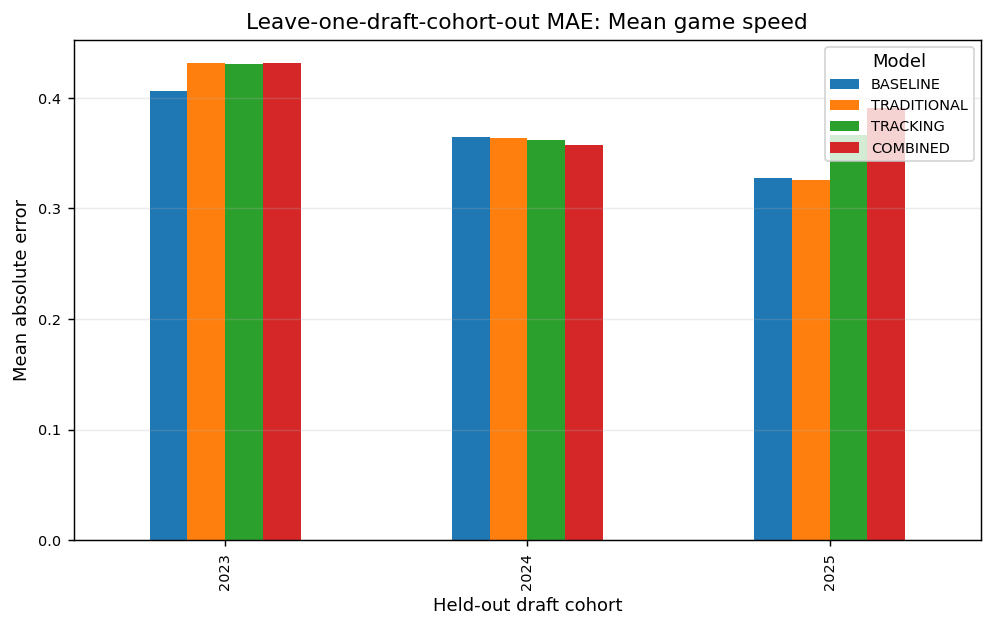

Exported: figure_07_loco_game_mean_speed_raw_median


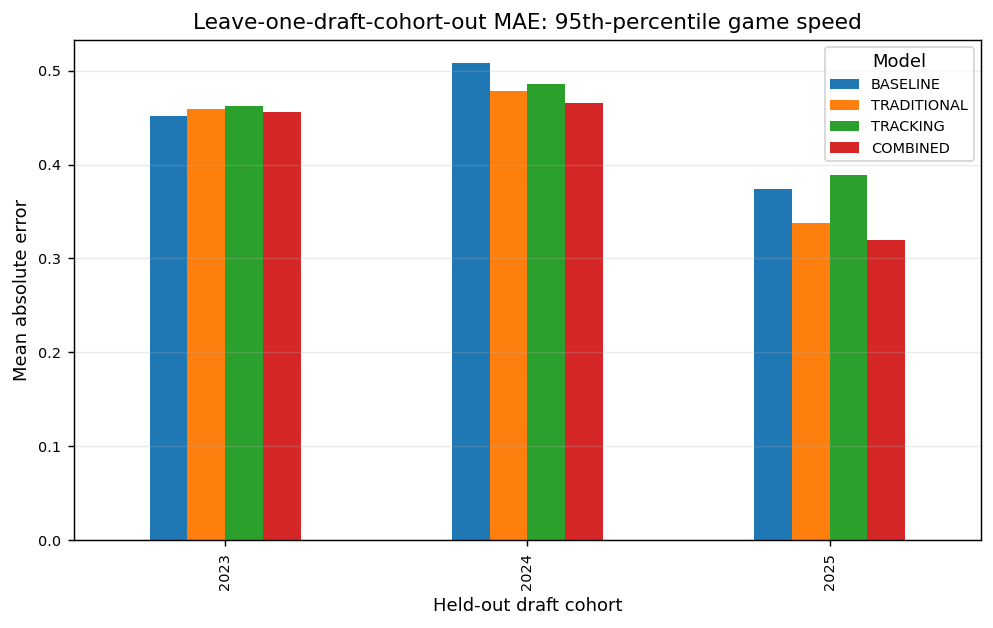

Exported: figure_08_loco_game_p95_speed_raw_median


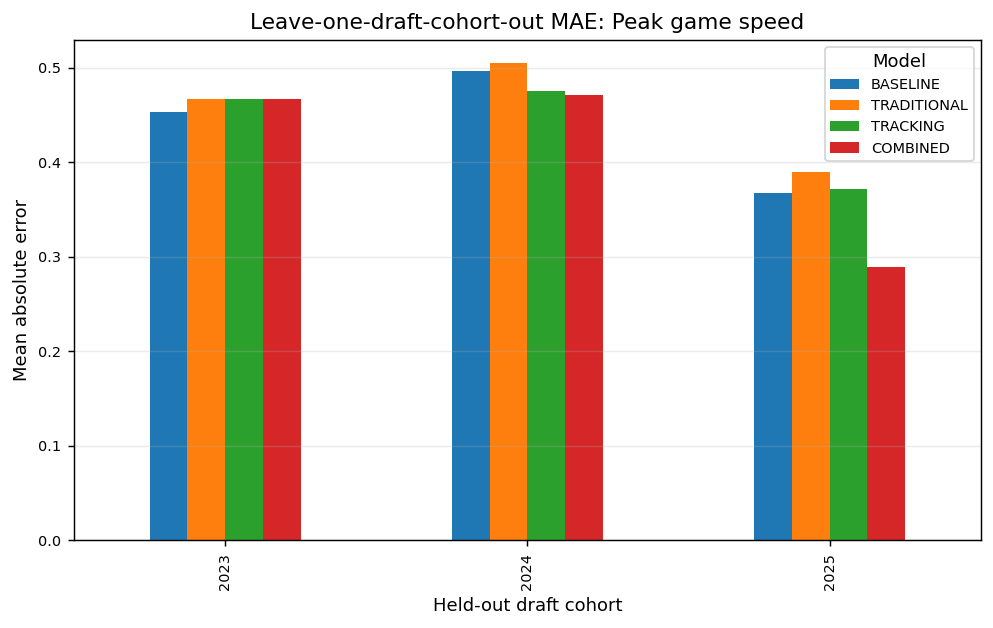

Exported: figure_09_loco_game_peak_speed_raw_median


In [7]:

# ============================================================
# FIGURES 7–9: LOCO SPEED PERFORMANCE
# ============================================================

for outcome in SPEED_OUTCOMES:

    subset = loco[
        loco["outcome"] == outcome
    ].copy()

    subset["held_out_draft_year"] = pd.to_numeric(
        subset["held_out_draft_year"]
    )

    pivot = subset.pivot(
        index="held_out_draft_year",
        columns="model",
        values="mae",
    )

    pivot = pivot.reindex(
        columns=MODEL_ORDER
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    pivot.plot(
        kind="bar",
        ax=ax,
    )

    ax.set_title(
        f"Leave-one-draft-cohort-out MAE: {outcome_label(outcome)}"
    )

    ax.set_xlabel("Held-out draft cohort")
    ax.set_ylabel("Mean absolute error")
    ax.legend(title="Model")
    ax.grid(axis="y", alpha=0.25)

    export_figure(
        fig,
        f"figure_{len(FIGURE_RECORDS)+1:02d}_loco_{outcome}",
        f"LOCO performance: {outcome_label(outcome)}",
        (
            "Mean absolute error when an entire draft cohort "
            "is held out. Cohort sample sizes are unequal; "
            "these estimates are cohort-specific and should "
            "not be interpreted as definitive future-season "
            "generalization."
        ),
    )


## 7. Combine predictor associations

Figure 10 visualizes univariate Spearman associations. These are marginal associations, not independent or causal effects.


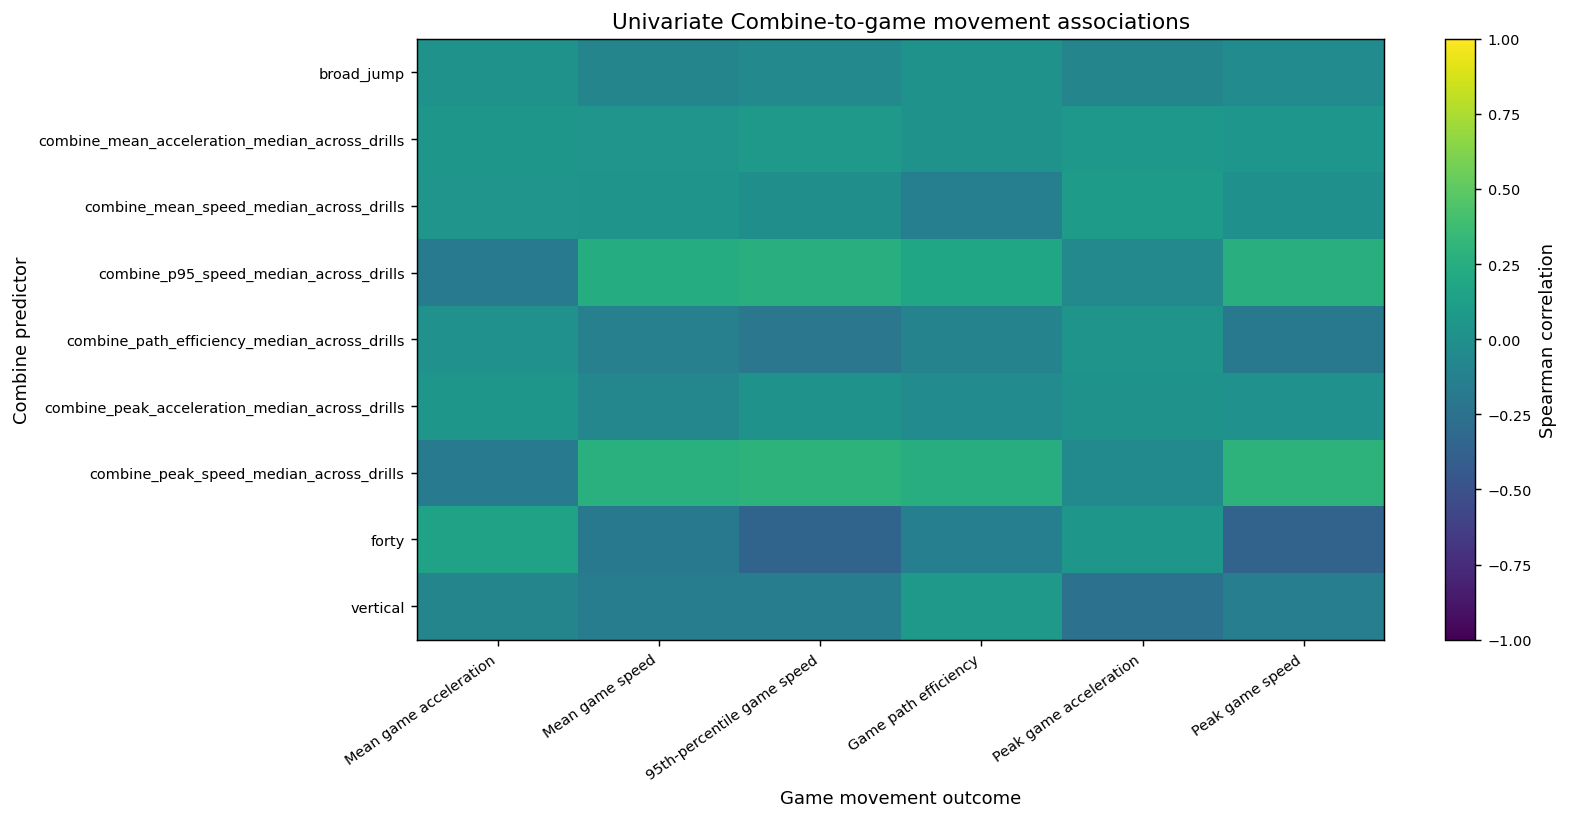

Exported: figure_10_predictor_spearman_heatmap


In [8]:

# ============================================================
# FIGURE 10: SPEARMAN ASSOCIATION HEATMAP
# ============================================================

association_heat = associations.pivot(
    index="predictor",
    columns="outcome",
    values="spearman_rho",
)

fig, ax = plt.subplots(
    figsize=(12, max(6, 0.48 * len(association_heat)))
)

im = ax.imshow(
    association_heat.to_numpy(dtype=float),
    aspect="auto",
    vmin=-1,
    vmax=1,
)

ax.set_xticks(
    np.arange(len(association_heat.columns))
)

ax.set_xticklabels(
    [outcome_label(x) for x in association_heat.columns],
    rotation=35,
    ha="right",
)

ax.set_yticks(
    np.arange(len(association_heat.index))
)

ax.set_yticklabels(
    association_heat.index
)

ax.set_title(
    "Univariate Combine-to-game movement associations"
)

ax.set_xlabel("Game movement outcome")
ax.set_ylabel("Combine predictor")

fig.colorbar(
    im,
    ax=ax,
    label="Spearman correlation",
)

export_figure(
    fig,
    "figure_10_predictor_spearman_heatmap",
    "Univariate Combine-to-game movement associations",
    (
        "Spearman rank correlations between nine Combine "
        "predictors and six game movement outcomes. "
        "These are univariate associations and do not "
        "represent adjusted independent effects or causality."
    ),
)


## 8. Tracking-feature ablation

Figure 11 compares the speed-feature ablation specifications.


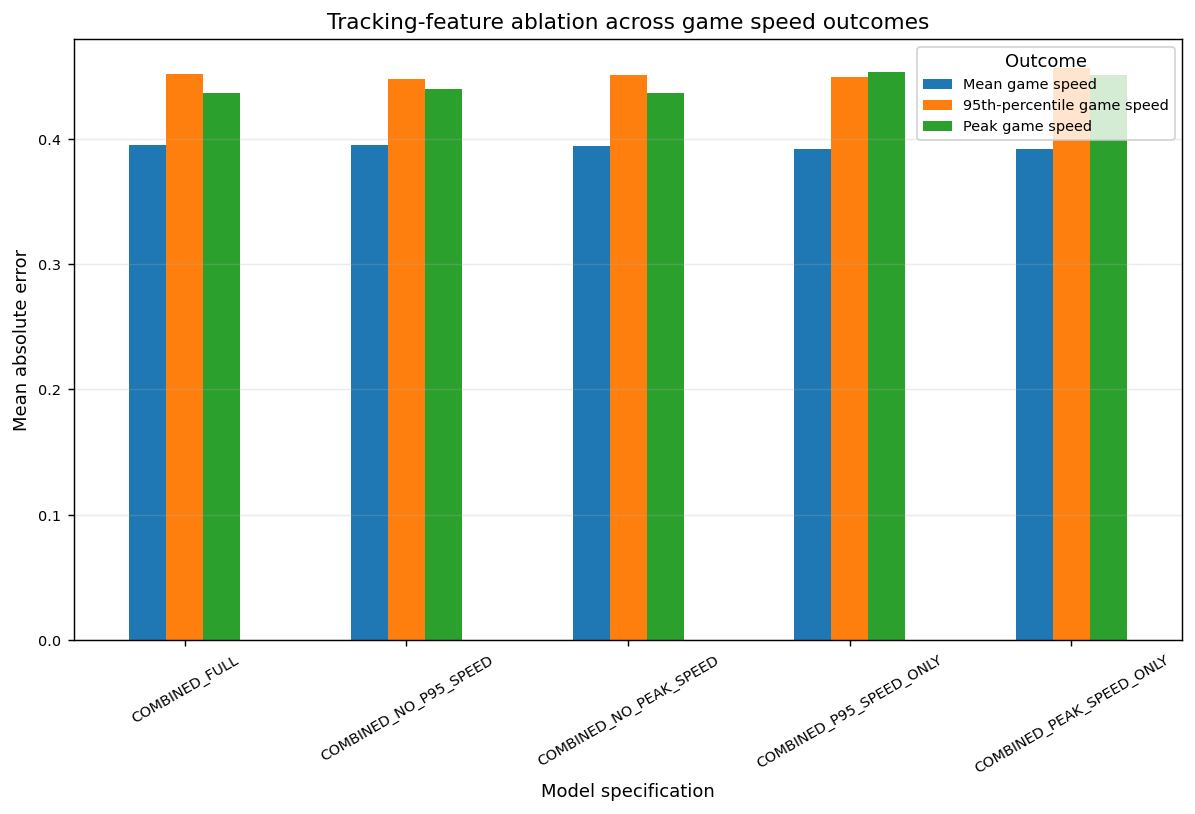

Exported: figure_11_tracking_feature_ablation


In [9]:

# ============================================================
# FIGURE 11: SPEED FEATURE ABLATION
# ============================================================

ablation_speed = ablation[
    ablation["outcome"].isin(SPEED_OUTCOMES)
].copy()

ablation_speed["mae"] = pd.to_numeric(
    ablation_speed["mae"],
    errors="coerce",
)

pivot = ablation_speed.pivot(
    index="model",
    columns="outcome",
    values="mae",
)

fig, ax = plt.subplots(figsize=(11, 6))

pivot.plot(
    kind="bar",
    ax=ax,
)

ax.set_title(
    "Tracking-feature ablation across game speed outcomes"
)

ax.set_xlabel("Model specification")
ax.set_ylabel("Mean absolute error")
ax.legend(
    [outcome_label(x) for x in pivot.columns],
    title="Outcome",
)

ax.tick_params(
    axis="x",
    rotation=30,
)

ax.grid(axis="y", alpha=0.25)

export_figure(
    fig,
    "figure_11_tracking_feature_ablation",
    "Tracking-feature ablation across game speed outcomes",
    (
        "Comparison of full and ablated tracking-feature "
        "specifications across mean, P95 and peak game speed. "
        "The results are descriptive and do not establish "
        "that an individual feature causes improved prediction."
    ),
)


## 9. Eligibility sample-size sensitivity

Figure 12 shows how the eligible player-season and receiver sample sizes vary across minimum-play thresholds.


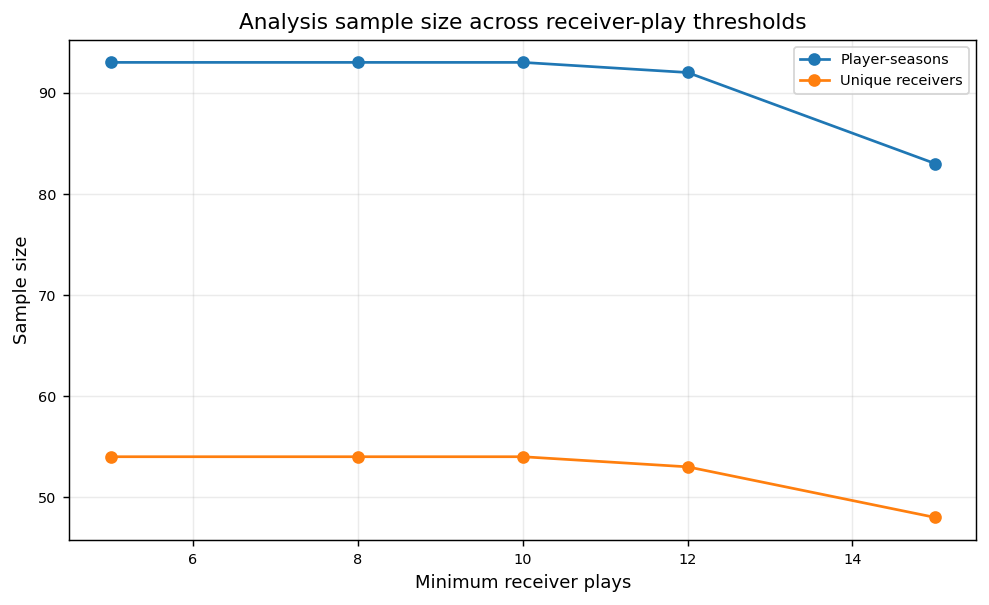

Exported: figure_12_eligibility_sample_size


In [10]:

# ============================================================
# FIGURE 12: ELIGIBILITY SAMPLE SIZE
# ============================================================

sample_sizes = (
    eligibility[
        ["threshold", "player_seasons", "unique_receivers"]
    ]
    .drop_duplicates()
    .sort_values("threshold")
)

sample_sizes.to_csv(
    TABLE_DIR / "eligibility_sample_sizes.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    sample_sizes["threshold"],
    sample_sizes["player_seasons"],
    marker="o",
    label="Player-seasons",
)

ax.plot(
    sample_sizes["threshold"],
    sample_sizes["unique_receivers"],
    marker="o",
    label="Unique receivers",
)

ax.set_title(
    "Analysis sample size across receiver-play thresholds"
)

ax.set_xlabel("Minimum receiver plays")
ax.set_ylabel("Sample size")

ax.legend()
ax.grid(alpha=0.25)

export_figure(
    fig,
    "figure_12_eligibility_sample_size",
    "Analysis sample size across receiver-play thresholds",
    (
        "Eligible player-season and receiver counts across "
        "minimum receiver-play thresholds of 5, 8, 10, 12 "
        "and 15. The threshold-10 sample contains 93 "
        "player-seasons and 54 receivers."
    ),
)


## 10. Supplementary model stability and coefficient tables

The following outputs provide additional diagnostic evidence for the research paper.


In [11]:

# ============================================================
# 13. SUPPLEMENTARY TABLE EXPORTS
# ============================================================

stability.to_csv(
    TABLE_DIR / "fold_stability.csv",
    index=False,
)

coefficients.to_csv(
    TABLE_DIR / "coefficient_stability.csv",
    index=False,
)

associations.to_csv(
    TABLE_DIR / "univariate_associations.csv",
    index=False,
)

ablation.to_csv(
    TABLE_DIR / "feature_ablation.csv",
    index=False,
)

loco.to_csv(
    TABLE_DIR / "loco_results.csv",
    index=False,
)

nested.to_csv(
    TABLE_DIR / "nested_cv_results.csv",
    index=False,
)

# Model stability summary.
stability_numeric = stability.copy()

for col in [
    "mean_mae_difference",
    "median_mae_difference",
    "folds_better",
    "folds_worse",
]:
    stability_numeric[col] = pd.to_numeric(
        stability_numeric[col],
        errors="coerce",
    )

stability_summary = (
    stability_numeric.groupby(
        ["outcome", "model"],
        as_index=False,
    )
    .agg(
        mean_fold_mae_difference=("mean_mae_difference", "mean"),
        median_fold_mae_difference=("median_mae_difference", "median"),
        mean_folds_better=("folds_better", "mean"),
        mean_folds_worse=("folds_worse", "mean"),
    )
)

stability_summary.to_csv(
    TABLE_DIR / "model_stability_summary.csv",
    index=False,
)

# Coefficient stability summary.
coefficient_numeric = coefficients.copy()

coefficient_numeric["coefficient_sd"] = pd.to_numeric(
    coefficient_numeric["coefficient_sd"],
    errors="coerce",
)

coefficient_summary = (
    coefficient_numeric.groupby(
        ["outcome", "model"],
        as_index=False,
    )
    .agg(
        mean_coefficient_sd=("coefficient_sd", "mean"),
        median_coefficient_sd=("coefficient_sd", "median"),
    )
)

coefficient_summary.to_csv(
    TABLE_DIR / "coefficient_variability_summary.csv",
    index=False,
)

print("Supplementary diagnostic tables exported.")


Supplementary diagnostic tables exported.


## 11. Figure captions and research interpretation

This section records the intended interpretation and limitations of the visual evidence.


In [12]:

# ============================================================
# 14. FIGURE CATALOGUE AND INTERPRETATION
# ============================================================

figure_catalogue = pd.DataFrame(FIGURE_RECORDS)

figure_catalogue.to_csv(
    TABLE_DIR / "publication_figure_catalogue.csv",
    index=False,
)

interpretation = {
    "main_conclusion": (
        "Combine movement characteristics show some associations "
        "with NFL game movement, but the study has not established "
        "consistent incremental predictive accuracy from tracking-derived "
        "features beyond traditional Combine measurements."
    ),

    "uncertainty": (
        "Receiver-level bootstrap confidence intervals for the primary "
        "P95 and peak speed comparisons include zero."
    ),

    "generalization": (
        "LOCO results are cohort-specific and affected by unequal "
        "sample sizes."
    ),

    "limitations": [
        "93 player-seasons from 54 receivers in the core modeling sample.",
        "Complete-case eligibility requirements.",
        "Strong correlation between some Combine speed predictors.",
        "Coefficient variability across validation folds.",
        "Observational design.",
        "No causal inference.",
    ],

    "visualization_warning": (
        "Outcome scales differ. Do not compare raw MAE values across "
        "different outcome types as if they were the same measurement."
    ),
}

(OUT / "figure_interpretation.json").write_text(
    json.dumps(interpretation, indent=2),
    encoding="utf-8",
)

print("Figure catalogue:")
display(figure_catalogue)

print("\nResearch interpretation:")
print(json.dumps(interpretation, indent=2))


Figure catalogue:


,figure_id,title,caption,png_path,pdf_path,png_bytes,pdf_bytes,png_sha256,pdf_sha256
0,figure_01_nested_game_mean_speed_raw_median,Nested cross-validation MAE: Mean game speed,Out-of-fold mean absolute error for the baseli...,reports\publication_visualizations\png\figure_...,reports\publication_visualizations\pdf\figure_...,108608,15778,b2907026630fd58a23a3e37760ed895e44451b1c287d36...,6e56feaebcd268c82837b250021687aedd721276e61991...
1,figure_02_nested_game_p95_speed_raw_median,Nested cross-validation MAE: 95th-percentile g...,Out-of-fold mean absolute error for the baseli...,reports\publication_visualizations\png\figure_...,reports\publication_visualizations\pdf\figure_...,103164,16389,c75376a48faf541b1daf824814cdc5fc2709984a05c524...,8065b2aefe61db62e29f4d7a2969fd86b60843c9201d3f...
2,figure_03_nested_game_peak_speed_raw_median,Nested cross-validation MAE: Peak game speed,Out-of-fold mean absolute error for the baseli...,reports\publication_visualizations\png\figure_...,reports\publication_visualizations\pdf\figure_...,100288,16148,3713726d557ea09c38d939bb427f4d09b10fcbc591c27f...,fcdf0016b7e5f0c74725c6327354c882bad3c7b2d7a922...
3,figure_04_all_outcome_mae_heatmap,Nested cross-validation MAE across all outcomes,Heatmap of out-of-fold MAE for six game moveme...,reports\publication_visualizations\png\figure_...,reports\publication_visualizations\pdf\figure_...,198130,36410,85bd19bbe1400674f5551869838888fb70161e7292f8d3...,4abfbd3bfaa16fc3e4b2c72e7e8e15464ea836f8eac053...
4,figure_05_bootstrap_game_p95_speed_raw_median,Receiver-level bootstrap: 95th-percentile game...,Receiver-level bootstrap comparison of MAE dif...,reports\publication_visualizations\png\figure_...,reports\publication_visualizations\pdf\figure_...,75467,16550,1c53272e70b07ae8f7da0c2a5f8e01138f908c0246d98c...,69232b019876f408bc9a9494483ddfaf129846c9d8fe88...
5,figure_06_bootstrap_game_peak_speed_raw_median,Receiver-level bootstrap: Peak game speed,Receiver-level bootstrap comparison of MAE dif...,reports\publication_visualizations\png\figure_...,reports\publication_visualizations\pdf\figure_...,74260,16488,871eda099aeaa4cb01c6ba963461b4fa64ba5b15f2819e...,45582917860e9cfb1d5da37015e78d59359819aa564122...
6,figure_07_loco_game_mean_speed_raw_median,LOCO performance: Mean game speed,Mean absolute error when an entire draft cohor...,reports\publication_visualizations\png\figure_...,reports\publication_visualizations\pdf\figure_...,90393,16679,aa37f5ac47c6a50857f5bf907e724ec4404e79546b4f78...,969cf51cb3190cf7e23ec0d4ccc7cb13a3a6cea543c406...
7,figure_08_loco_game_p95_speed_raw_median,LOCO performance: 95th-percentile game speed,Mean absolute error when an entire draft cohor...,reports\publication_visualizations\png\figure_...,reports\publication_visualizations\pdf\figure_...,96672,17349,189535c5b8c9995729e2efce78afb1be6a3b548c18f81e...,172b5b9422def3949cfea7e4a8a68d1e92fe93863a1fc2...
8,figure_09_loco_game_peak_speed_raw_median,LOCO performance: Peak game speed,Mean absolute error when an entire draft cohor...,reports\publication_visualizations\png\figure_...,reports\publication_visualizations\pdf\figure_...,93340,17192,3eed14b76a380a4b8056c2e7b40eb1faa2e34c9bc8fd1c...,88e75d4d27cecd196d39e399dfef6e46682c4ab0537822...
9,figure_10_predictor_spearman_heatmap,Univariate Combine-to-game movement associations,Spearman rank correlations between nine Combin...,reports\publication_visualizations\png\figure_...,reports\publication_visualizations\pdf\figure_...,318575,43187,ef92e19146971799fad29821657b85fc9d06ff030cd9ee...,0d516e8073b34b75f0e81f6d98515da7dc302c04ad34a1...



Research interpretation:
{
  "main_conclusion": "Combine movement characteristics show some associations with NFL game movement, but the study has not established consistent incremental predictive accuracy from tracking-derived features beyond traditional Combine measurements.",
  "uncertainty": "Receiver-level bootstrap confidence intervals for the primary P95 and peak speed comparisons include zero.",
  "generalization": "LOCO results are cohort-specific and affected by unequal sample sizes.",
  "limitations": [
    "93 player-seasons from 54 receivers in the core modeling sample.",
    "Complete-case eligibility requirements.",
    "Strong correlation between some Combine speed predictors.",
    "Coefficient variability across validation folds.",
    "Observational design.",
    "No causal inference."
  ],
  "visualization_warning": "Outcome scales differ. Do not compare raw MAE values across different outcome types as if they were the same measurement."
}


## 12. Final visualization reproducibility audit


In [13]:

# ============================================================
# 15. FINAL AUDIT AND MANIFEST
# ============================================================

if len(FIGURE_RECORDS) != 12:
    raise AssertionError(
        f"Expected 12 figures, found {len(FIGURE_RECORDS)}"
    )

for record in FIGURE_RECORDS:

    png = ROOT / record["png_path"]
    pdf = ROOT / record["pdf_path"]

    if not png.is_file() or png.stat().st_size < 5000:
        raise AssertionError(
            f"Invalid or undersized PNG: {png}"
        )

    if not pdf.is_file() or pdf.stat().st_size < 1000:
        raise AssertionError(
            f"Invalid or undersized PDF: {pdf}"
        )

    raw = png.read_bytes()

    if raw[:8] != b"\x89PNG\r\n\x1a\n":
        raise AssertionError(
            f"Invalid PNG signature: {png}"
        )

    width, height = struct.unpack(">II", raw[16:24])

    if width < 500 or height < 300:
        raise AssertionError(
            f"Unexpected figure dimensions: {png}"
        )

manifest = {
    "project": "WR-MovementIQ",
    "notebook": "12_publication_quality_visualization.ipynb",
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "source_artifacts": SOURCE_AUDIT,
    "figure_count": len(FIGURE_RECORDS),
    "png_count": len(list(PNG_DIR.glob("*.png"))),
    "pdf_count": len(list(PDF_DIR.glob("*.pdf"))),
    "figures": FIGURE_RECORDS,
    "visualization_status": "PASS",
    "model_training_performed": False,
    "data_modified": False,
}

manifest_path = OUT / "publication_visualization_manifest.json"

manifest_path.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

print("\n" + "=" * 75)
print("NOTEBOOK 12 — PUBLICATION VISUALIZATION COMPLETE")
print("=" * 75)

print("Figures:", len(FIGURE_RECORDS))
print("PNG files:", len(list(PNG_DIR.glob("*.png"))))
print("PDF files:", len(list(PDF_DIR.glob("*.pdf"))))
print("Source tables:", len(SOURCE_AUDIT))
print("Model training:", "NOT PERFORMED")
print("Data modification:", "NOT PERFORMED")
print("Audit:", "PASS")
print("Manifest:", manifest_path)



NOTEBOOK 12 — PUBLICATION VISUALIZATION COMPLETE
Figures: 12
PNG files: 12
PDF files: 12
Source tables: 9
Model training: NOT PERFORMED
Data modification: NOT PERFORMED
Audit: PASS
Manifest: D:\PROJECTS\WR-MovementIQ\reports\publication_visualizations\publication_visualization_manifest.json
